In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

LIVE_FEATURES = [
    "dur",
    "spkts",
    "dpkts",
    "sbytes",
    "dbytes",
    "rate",
    "sinpkt",
    "dinpkt",
    "smean",
    "dmean"
]

live_df = pd.read_csv("../data/live_flows.csv")

unsw_df = pd.read_csv(
    "../data/UNSW_NB15_training-set.csv"
)

unsw_normal = unsw_df[
    unsw_df["label"] == 0
].copy()

unsw_attack = unsw_df[
    unsw_df["label"] == 1
].copy()

print("Live flows:", len(live_df))
print("UNSW normal:", len(unsw_normal))
print("UNSW attacks:", len(unsw_attack))

Live flows: 173
UNSW normal: 56000
UNSW attacks: 119341


In [2]:
print("LIVE PREDICTIONS")
print("=" * 40)

print(
    live_df["prediction"]
    .value_counts()
)

print()

print(
    live_df["prediction"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print()

print(
    "Average risk:",
    round(
        live_df["risk_score"].mean(),
        2
    )
)

print(
    "Median risk:",
    round(
        live_df["risk_score"].median(),
        2
    )
)

LIVE PREDICTIONS
prediction
ATTACK    119
NORMAL     54
Name: count, dtype: int64

prediction
ATTACK    68.79
NORMAL    31.21
Name: proportion, dtype: float64

Average risk: 64.2
Median risk: 62.67


In [3]:
comparison_rows = []

for feature in LIVE_FEATURES:

    comparison_rows.append(
        {
            "feature": feature,

            "live_median":
                live_df[feature].median(),

            "normal_median":
                unsw_normal[feature].median(),

            "attack_median":
                unsw_attack[feature].median(),

            "live_mean":
                live_df[feature].mean(),

            "normal_mean":
                unsw_normal[feature].mean(),

            "attack_mean":
                unsw_attack[feature].mean(),
        }
    )

comparison_df = pd.DataFrame(
    comparison_rows
)

comparison_df.round(3)

,feature,live_median,normal_median,attack_median,live_mean,normal_mean,attack_mean
0,dur,0.595,0.039,0.000,4.946,1.017,1.520
1,spkts,14.000,12.000,2.000,42.549,30.725,15.406
2,dpkts,14.000,10.000,0.000,158.000,38.058,10.013
3,sbytes,3297.000,1470.000,200.000,12728.133,4105.703,11068.655
4,dbytes,7993.000,1112.000,0.000,192091.746,31049.463,7364.456
5,rate,57.685,1382.257,111111.107,151.561,13799.312,133699.691
6,sinpkt,43.179,1.431,0.009,347.808,2847.882,112.290
7,dinpkt,20.738,0.911,0.000,244.954,121.197,72.740
8,smean,224.692,73.000,76.000,303.598,139.978,135.238
9,dmean,506.467,89.000,0.000,554.092,253.067,63.691


In [4]:
range_rows = []

for feature in LIVE_FEATURES:

    range_rows.append(
        {
            "feature": feature,

            "live_p10":
                live_df[feature].quantile(0.10),

            "live_p50":
                live_df[feature].quantile(0.50),

            "live_p90":
                live_df[feature].quantile(0.90),

            "normal_p10":
                unsw_normal[feature].quantile(0.10),

            "normal_p50":
                unsw_normal[feature].quantile(0.50),

            "normal_p90":
                unsw_normal[feature].quantile(0.90),

            "attack_p10":
                unsw_attack[feature].quantile(0.10),

            "attack_p50":
                unsw_attack[feature].quantile(0.50),

            "attack_p90":
                unsw_attack[feature].quantile(0.90),
        }
    )

ranges_df = pd.DataFrame(
    range_rows
)

ranges_df.round(3)

,feature,live_p10,live_p50,live_p90,normal_p10,normal_p50,normal_p90,attack_p10,attack_p50,attack_p90
0,dur,0.076,0.595,18.884,0.000,0.039,1.197,0.000,0.000,1.676
1,spkts,3.000,14.000,74.800,2.000,12.000,66.000,2.000,2.000,20.000
2,dpkts,3.000,14.000,168.200,0.000,10.000,66.000,0.000,0.000,12.000
3,sbytes,248.200,3297.000,39801.000,130.000,1470.000,7818.000,114.000,200.000,2190.000
4,dbytes,248.000,7993.000,171925.400,0.000,1112.000,48710.000,0.000,0.000,1660.000
5,rate,3.086,57.685,321.698,15.029,1382.257,7021.780,15.616,111111.107,333333.322
6,sinpkt,12.565,43.179,621.278,0.009,1.431,120.705,0.003,0.009,121.457
7,dinpkt,0.286,20.738,595.082,0.000,0.911,92.425,0.000,0.000,122.976
8,smean,78.120,224.692,666.251,53.000,73.000,252.000,56.000,76.000,217.000
9,dmean,82.667,506.467,1265.710,0.000,89.000,786.000,0.000,0.000,97.000


In [5]:
print("LIVE PROTOCOLS")
print(
    live_df["proto"]
    .value_counts()
)

print()

print("UNSW NORMAL PROTOCOLS")
print(
    unsw_normal["proto"]
    .value_counts()
    .head(10)
)

print()

print("UNSW ATTACK PROTOCOLS")
print(
    unsw_attack["proto"]
    .value_counts()
    .head(10)
)

LIVE PROTOCOLS
proto
tcp    152
udp     21
Name: count, dtype: int64

UNSW NORMAL PROTOCOLS
proto
tcp     39121
udp     13922
arp      2859
ospf       64
igmp       18
icmp       15
rtp         1
Name: count, dtype: int64

UNSW ATTACK PROTOCOLS
proto
udp       49361
tcp       40825
unas      12084
ospf       2531
sctp       1150
any         300
gre         225
sun-nd      201
swipe       201
mobile      201
Name: count, dtype: int64


In [6]:
difference_rows = []

for feature in LIVE_FEATURES:

    live_median = (
        live_df[feature].median()
    )

    normal_median = (
        unsw_normal[feature].median()
    )

    attack_median = (
        unsw_attack[feature].median()
    )

    normal_scale = (
        unsw_normal[feature]
        .quantile(0.75)
        -
        unsw_normal[feature]
        .quantile(0.25)
    )

    if normal_scale == 0:
        normal_scale = 1

    distance_from_normal = abs(
        live_median
        -
        normal_median
    ) / normal_scale

    difference_rows.append(
        {
            "feature":
                feature,

            "live_median":
                live_median,

            "normal_median":
                normal_median,

            "attack_median":
                attack_median,

            "distance_from_normal":
                distance_from_normal
        }
    )

difference_df = (
    pd.DataFrame(
        difference_rows
    )
    .sort_values(
        "distance_from_normal",
        ascending=False
    )
)

difference_df.round(3)

,feature,live_median,normal_median,attack_median,distance_from_normal
8,smean,224.692,73.000,76.000,2.137
9,dmean,506.467,89.000,0.000,0.973
0,dur,0.595,0.039,0.000,0.872
6,sinpkt,43.179,1.431,0.009,0.730
4,dbytes,7993.000,1112.000,0.000,0.689
3,sbytes,3297.000,1470.000,200.000,0.614
7,dinpkt,20.738,0.911,0.000,0.592
5,rate,57.685,1382.257,111111.107,0.421
2,dpkts,14.000,10.000,0.000,0.105
1,spkts,14.000,12.000,2.000,0.056


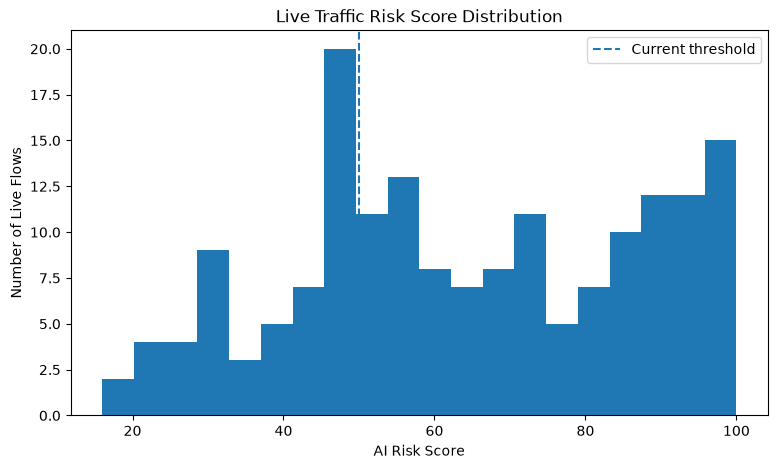

In [7]:
plt.figure(
    figsize=(9, 5)
)

plt.hist(
    live_df["risk_score"],
    bins=20
)

plt.axvline(
    50,
    linestyle="--",
    label="Current threshold"
)

plt.xlabel(
    "AI Risk Score"
)

plt.ylabel(
    "Number of Live Flows"
)

plt.title(
    "Live Traffic Risk Score Distribution"
)

plt.legend()

plt.show()

In [8]:
total_live = len(
    live_df
)

predicted_attacks = (
    live_df["prediction"]
    .eq("ATTACK")
    .sum()
)

predicted_normal = (
    live_df["prediction"]
    .eq("NORMAL")
    .sum()
)

false_positive_rate_baseline = (
    predicted_attacks
    /
    total_live
    *
    100
)

print(
    "Total baseline flows:",
    total_live
)

print(
    "Predicted ATTACK:",
    predicted_attacks
)

print(
    "Predicted NORMAL:",
    predicted_normal
)

print(
    "Apparent false-positive rate:",
    round(
        false_positive_rate_baseline,
        2
    ),
    "%"
)

Total baseline flows: 173
Predicted ATTACK: 119
Predicted NORMAL: 54
Apparent false-positive rate: 68.79 %


In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

candidate_feature_sets = {
    
    "all_11": [
        "dur",
        "proto",
        "spkts",
        "dpkts",
        "sbytes",
        "dbytes",
        "rate",
        "sinpkt",
        "dinpkt",
        "smean",
        "dmean",
    ],
    
    "without_packet_means": [
        "dur",
        "proto",
        "spkts",
        "dpkts",
        "sbytes",
        "dbytes",
        "rate",
        "sinpkt",
        "dinpkt",
    ],
    
    "stable_7": [
        "proto",
        "spkts",
        "dpkts",
        "sbytes",
        "dbytes",
        "rate",
        "dur",
    ],
    
    "stable_5": [
        "proto",
        "spkts",
        "dpkts",
        "sbytes",
        "dbytes",
    ],
    
    "packets_only": [
        "proto",
        "spkts",
        "dpkts",
    ],
}

In [13]:
train_df = pd.read_csv(
    "../data/UNSW_NB15_training-set.csv"
)

test_df = pd.read_csv(
    "../data/UNSW_NB15_testing-set.csv"
)

print("Training:", train_df.shape)
print("Testing:", test_df.shape)

print("train_df loaded:", len(train_df))
print("test_df loaded:", len(test_df))

Training: (175341, 45)
Testing: (82332, 45)
train_df loaded: 175341
test_df loaded: 82332


In [15]:
results = []

for model_name, features in candidate_feature_sets.items():

    categorical = [
        feature
        for feature in features
        if feature == "proto"
    ]

    numeric = [
        feature
        for feature in features
        if feature != "proto"
    ]

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "categorical",
                OneHotEncoder(
                    handle_unknown="ignore"
                ),
                categorical
            ),
            (
                "numeric",
                "passthrough",
                numeric
            )
        ]
    )

    candidate_model = Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor
            ),
            (
                "classifier",
                RandomForestClassifier(
                    n_estimators=100,
                    random_state=42,
                    n_jobs=-1,
                    class_weight="balanced"
                )
            )
        ]
    )

    candidate_model.fit(
        train_df[features],
        train_df["label"]
    )

    predictions = candidate_model.predict(
        test_df[features]
    )

    results.append(
        {
            "model": model_name,
            "features": len(features),

            "accuracy": accuracy_score(
                test_df["label"],
                predictions
            ),

            "precision": precision_score(
                test_df["label"],
                predictions
            ),

            "recall": recall_score(
                test_df["label"],
                predictions
            ),

            "f1": f1_score(
                test_df["label"],
                predictions
            ),
        }
    )

results_df = pd.DataFrame(results)

results_df.round(4)

,model,features,accuracy,precision,recall,f1
0,all_11,11,0.8898,0.8605,0.9546,0.9051
1,without_packet_means,9,0.8850,0.8537,0.9548,0.9014
2,stable_7,7,0.8833,0.8523,0.9533,0.9000
3,stable_5,5,0.8937,0.8746,0.9419,0.9070
4,packets_only,3,0.8008,0.7482,0.9619,0.8417


In [ ]:
live_results = []

trained_models = {}

for model_name, features in candidate_feature_sets.items():

    categorical = [
        feature
        for feature in features
        if feature == "proto"
    ]

    numeric = [
        feature
        for feature in features
        if feature != "proto"
    ]

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "categorical",
                OneHotEncoder(
                    handle_unknown="ignore"
                ),
                categorical
            ),
            (
                "numeric",
                "passthrough",
                numeric
            )
        ]
    )

    candidate_model = Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor
            ),
            (
                "classifier",
                RandomForestClassifier(
                    n_estimators=100,
                    random_state=42,
                    n_jobs=-1,
                    class_weight="balanced"
                )
            )
        ]
    )

    candidate_model.fit(
        train_df[features],
        train_df["label"]
    )

    trained_models[
        model_name
    ] = candidate_model

    probabilities = (
        candidate_model.predict_proba(
            live_df[features]
        )[:, 1]
    )

    predictions = (
        probabilities >= 0.50
    ).astype(int)

    live_results.append(
        {
            "model":
                model_name,

            "features":
                len(features),

            "live_attack_predictions":
                int(predictions.sum()),

            "live_normal_predictions":
                int(
                    len(predictions)
                    -
                    predictions.sum()
                ),

            "live_attack_percent":
                predictions.mean()
                * 100,

            "average_live_risk":
                probabilities.mean()
                * 100,

            "median_live_risk":
                np.median(
                    probabilities
                )
                * 100,
        }
    )

live_results_df = pd.DataFrame(
    live_results
)

live_results_df.round(2)

In [1]:
import pandas as pd
import numpy as np

train_df = pd.read_csv(
    "../data/UNSW_NB15_training-set.csv"
)

test_df = pd.read_csv(
    "../data/UNSW_NB15_testing-set.csv"
)

live_v2_df = pd.read_csv(
    "../data/live_flows_v2.csv"
)


def create_direction_invariant_features(df):

    result = pd.DataFrame()

    result["proto"] = df["proto"]
    result["dur"] = df["dur"]

    result["total_packets"] = (
        df["spkts"] + df["dpkts"]
    )

    result["total_bytes"] = (
        df["sbytes"] + df["dbytes"]
    )

    result["packet_difference"] = (
        df["spkts"] - df["dpkts"]
    ).abs()

    result["byte_difference"] = (
        df["sbytes"] - df["dbytes"]
    ).abs()

    result["min_packets"] = df[
        ["spkts", "dpkts"]
    ].min(axis=1)

    result["max_packets"] = df[
        ["spkts", "dpkts"]
    ].max(axis=1)

    result["min_bytes"] = df[
        ["sbytes", "dbytes"]
    ].min(axis=1)

    result["max_bytes"] = df[
        ["sbytes", "dbytes"]
    ].max(axis=1)

    result["average_packet_size"] = (
        result["total_bytes"]
        /
        result["total_packets"].replace(0, 1)
    )

    return result


X_train_v2 = create_direction_invariant_features(
    train_df
)

X_test_v2 = create_direction_invariant_features(
    test_df
)

X_live_v2 = create_direction_invariant_features(
    live_v2_df
)


print("Training:", X_train_v2.shape)
print("Testing:", X_test_v2.shape)
print("Live V2:", X_live_v2.shape)

X_live_v2.head()

Training: (175341, 11)
Testing: (82332, 11)
Live V2: (105, 11)


,proto,dur,total_packets,total_bytes,packet_difference,byte_difference,min_packets,max_packets,min_bytes,max_bytes,average_packet_size
0,tcp,0.043295,5,334,1,78,2,3,128,206,66.800000
1,tcp,0.043088,5,334,1,78,2,3,128,206,66.800000
2,tcp,0.107048,5,334,1,78,2,3,128,206,66.800000
3,tcp,0.071122,6,348,0,12,3,3,168,180,58.000000
4,tcp,0.621758,31,15131,1,4891,15,16,5120,10011,488.096774


In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)


feature_names_v2 = list(
    X_train_v2.columns
)

categorical_features = [
    "proto"
]

numeric_features = [
    feature
    for feature in feature_names_v2
    if feature != "proto"
]


preprocessor_v2 = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        ),
        (
            "numeric",
            "passthrough",
            numeric_features
        )
    ]
)


live_model_v2 = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor_v2
        ),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=150,
                random_state=42,
                n_jobs=-1,
                class_weight="balanced"
            )
        )
    ]
)


live_model_v2.fit(
    X_train_v2,
    train_df["label"]
)


test_predictions = live_model_v2.predict(
    X_test_v2
)


print("=== UNSW TEST RESULTS ===")

print(
    "Accuracy:",
    round(
        accuracy_score(
            test_df["label"],
            test_predictions
        ),
        4
    )
)

print(
    "Precision:",
    round(
        precision_score(
            test_df["label"],
            test_predictions
        ),
        4
    )
)

print(
    "Recall:",
    round(
        recall_score(
            test_df["label"],
            test_predictions
        ),
        4
    )
)

print(
    "F1:",
    round(
        f1_score(
            test_df["label"],
            test_predictions
        ),
        4
    )
)

print()

print(
    "Confusion matrix:"
)

print(
    confusion_matrix(
        test_df["label"],
        test_predictions
    )
)


live_probabilities = (
    live_model_v2
    .predict_proba(
        X_live_v2
    )[:, 1]
)

live_predictions = (
    live_probabilities >= 0.50
).astype(int)


print()
print("=== REAL LIVE V2 BASELINE ===")

print(
    "Total:",
    len(live_predictions)
)

print(
    "ATTACK:",
    int(
        live_predictions.sum()
    )
)

print(
    "NORMAL:",
    int(
        len(live_predictions)
        -
        live_predictions.sum()
    )
)

print(
    "ATTACK percentage:",
    round(
        live_predictions.mean()
        * 100,
        2
    ),
    "%"
)

print(
    "Average risk:",
    round(
        live_probabilities.mean()
        * 100,
        2
    )
)

print(
    "Median risk:",
    round(
        np.median(
            live_probabilities
        )
        * 100,
        2
    )
)

=== UNSW TEST RESULTS ===
Accuracy: 0.8829
Precision: 0.8512
Recall: 0.9543
F1: 0.8998

Confusion matrix:
[[29435  7565]
 [ 2073 43259]]

=== REAL LIVE V2 BASELINE ===
Total: 105
ATTACK: 95
NORMAL: 10
ATTACK percentage: 90.48 %
Average risk: 80.42
Median risk: 87.33


In [3]:
threshold_results = []

test_probabilities = (
    live_model_v2
    .predict_proba(X_test_v2)[:, 1]
)

y_test = test_df["label"].to_numpy()

thresholds = [
    0.50,
    0.55,
    0.60,
    0.65,
    0.70,
    0.75,
    0.80,
    0.85,
    0.90,
    0.92,
    0.94,
    0.96,
    0.98,
    0.99,
]

for threshold in thresholds:

    # UNSW predictions
    unsw_predictions = (
        test_probabilities >= threshold
    ).astype(int)

    # Live baseline predictions
    live_threshold_predictions = (
        live_probabilities >= threshold
    ).astype(int)

    # Attack recall on UNSW
    attack_mask = (
        y_test == 1
    )

    attack_recall = (
        unsw_predictions[attack_mask].sum()
        /
        attack_mask.sum()
    )

    # False positive rate on UNSW normal traffic
    normal_mask = (
        y_test == 0
    )

    unsw_false_positive_rate = (
        unsw_predictions[normal_mask].sum()
        /
        normal_mask.sum()
    )

    # Baseline live traffic is assumed normal
    live_attack_percent = (
        live_threshold_predictions.mean()
        * 100
    )

    threshold_results.append(
        {
            "threshold": threshold,

            "UNSW_attack_recall_%":
                attack_recall * 100,

            "UNSW_normal_FP_%":
                unsw_false_positive_rate * 100,

            "Live_baseline_attack_%":
                live_attack_percent,
        }
    )


threshold_df = pd.DataFrame(
    threshold_results
)

threshold_df.round(2)

,threshold,UNSW_attack_recall_%,UNSW_normal_FP_%,Live_baseline_attack_%
0,0.50,95.47,20.64,90.48
1,0.55,94.59,17.32,81.90
2,0.60,93.92,14.96,79.05
3,0.65,93.33,12.85,78.10
4,0.70,92.39,11.83,76.19
5,0.75,91.80,10.43,70.48
6,0.80,91.00,8.88,64.76
7,0.85,89.93,7.21,56.19
8,0.90,88.57,5.75,45.71
9,0.92,87.63,5.09,40.95


In [4]:
import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    OneHotEncoder,
    FunctionTransformer,
    RobustScaler,
)
from sklearn.pipeline import Pipeline
from sklearn.ensemble import IsolationForest


# ==========================================================
# Load real live baseline
# ==========================================================

live_v3_df = pd.read_csv(
    "../data/live_flows_v2.csv"
)


LIVE_FEATURES = [
    "dur",
    "proto",
    "spkts",
    "dpkts",
    "sbytes",
    "dbytes",
    "rate",
    "sinpkt",
    "dinpkt",
    "smean",
    "dmean",
]


live_v3_df = (
    live_v3_df[LIVE_FEATURES]
    .dropna()
    .reset_index(drop=True)
)


print(
    "Total baseline flows:",
    len(live_v3_df)
)


print()
print("Protocol distribution:")

print(
    live_v3_df["proto"]
    .value_counts()
)


# ==========================================================
# Chronological split
#
# 70% training
# 15% calibration
# 15% final baseline test
# ==========================================================

total_rows = len(
    live_v3_df
)

train_end = int(
    total_rows * 0.70
)

calibration_end = int(
    total_rows * 0.85
)


X_train_live = (
    live_v3_df.iloc[
        :train_end
    ].copy()
)


X_calibration_live = (
    live_v3_df.iloc[
        train_end:
        calibration_end
    ].copy()
)


X_test_live = (
    live_v3_df.iloc[
        calibration_end:
    ].copy()
)


print()
print(
    "Training:",
    X_train_live.shape
)

print(
    "Calibration:",
    X_calibration_live.shape
)

print(
    "Test:",
    X_test_live.shape
)

Total baseline flows: 678

Protocol distribution:
proto
tcp    522
udp    156
Name: count, dtype: int64

Training: (474, 11)
Calibration: (102, 11)
Test: (102, 11)


In [5]:
numeric_features = [
    "dur",
    "spkts",
    "dpkts",
    "sbytes",
    "dbytes",
    "rate",
    "sinpkt",
    "dinpkt",
    "smean",
    "dmean",
]

categorical_features = [
    "proto"
]


# ==========================================================
# Numeric preprocessing
#
# log1p reduces extreme skew
# RobustScaler reduces sensitivity to outliers
# ==========================================================

numeric_pipeline = Pipeline(
    steps=[
        (
            "log_transform",
            FunctionTransformer(
                np.log1p
            )
        ),
        (
            "scaler",
            RobustScaler()
        ),
    ]
)


preprocessor_v3 = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_pipeline,
            numeric_features,
        ),
        (
            "protocol",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features,
        ),
    ]
)


# ==========================================================
# Isolation Forest
# ==========================================================

live_model_v3 = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor_v3
        ),
        (
            "model",
            IsolationForest(
                n_estimators=300,
                random_state=42,
                n_jobs=-1,
                contamination="auto",
            )
        ),
    ]
)


live_model_v3.fit(
    X_train_live
)


# ==========================================================
# Anomaly scores
#
# Higher number = more anomalous
# ==========================================================

calibration_scores = (
    -live_model_v3.score_samples(
        X_calibration_live
    )
)

test_scores = (
    -live_model_v3.score_samples(
        X_test_live
    )
)


# ==========================================================
# Compare possible alert thresholds
# ==========================================================

threshold_results = []


for percentile in [
    0.95,
    0.975,
    0.99,
]:

    threshold = np.quantile(
        calibration_scores,
        percentile
    )


    calibration_alerts = (
        calibration_scores
        >= threshold
    )


    test_alerts = (
        test_scores
        >= threshold
    )


    threshold_results.append(
        {
            "calibration_percentile":
                percentile,

            "anomaly_threshold":
                threshold,

            "calibration_alert_%":
                calibration_alerts.mean()
                * 100,

            "test_baseline_alert_%":
                test_alerts.mean()
                * 100,

            "test_alert_count":
                int(
                    test_alerts.sum()
                ),
        }
    )


v3_threshold_df = pd.DataFrame(
    threshold_results
)


v3_threshold_df.round(3)

,calibration_percentile,anomaly_threshold,calibration_alert_%,test_baseline_alert_%,test_alert_count
0,0.950,0.585,5.882,7.843,8
1,0.975,0.605,2.941,4.902,5
2,0.990,0.614,1.961,3.922,4


In [6]:
# ==========================================================
# Select threshold from calibration
# ==========================================================

selected_threshold = float(
    v3_threshold_df.loc[
        v3_threshold_df[
            "calibration_percentile"
        ] == 0.99,
        "anomaly_threshold"
    ].iloc[0]
)

print(
    "Selected threshold:",
    round(selected_threshold, 4)
)


# ==========================================================
# Helper for anomaly testing
# ==========================================================

def evaluate_anomaly_set(
    name,
    dataframe
):

    scores = (
        -live_model_v3.score_samples(
            dataframe
        )
    )

    alerts = (
        scores >= selected_threshold
    )

    return {
        "scenario": name,

        "flows":
            len(dataframe),

        "alerts":
            int(alerts.sum()),

        "alert_rate_%":
            alerts.mean() * 100,

        "average_score":
            scores.mean(),

        "median_score":
            np.median(scores),
    }


# ==========================================================
# Start from real normal flows
# ==========================================================

synthetic_base = (
    X_test_live
    .sample(
        n=min(
            100,
            len(X_test_live)
        ),
        random_state=42
    )
    .copy()
)


results = []


# ----------------------------------------------------------
# 1. Real unseen normal traffic
# ----------------------------------------------------------

results.append(
    evaluate_anomaly_set(
        "real_normal",
        synthetic_base
    )
)


# ----------------------------------------------------------
# 2. Extremely high packet rate
# ----------------------------------------------------------

high_rate = (
    synthetic_base.copy()
)

high_rate["rate"] = (
    high_rate["rate"] * 25
    + 1000
)

high_rate["dur"] = np.maximum(
    high_rate["dur"] * 0.10,
    0.01
)

results.append(
    evaluate_anomaly_set(
        "high_rate_burst",
        high_rate
    )
)


# ----------------------------------------------------------
# 3. Large outbound data spike
# ----------------------------------------------------------

outbound_spike = (
    synthetic_base.copy()
)

outbound_spike["sbytes"] = (
    outbound_spike["sbytes"]
    * 50
    + 100000
)

outbound_spike["spkts"] = (
    outbound_spike["spkts"]
    * 5
    + 20
)

outbound_spike["smean"] = (
    outbound_spike["smean"]
    * 5
    + 500
)

results.append(
    evaluate_anomaly_set(
        "outbound_data_spike",
        outbound_spike
    )
)


# ----------------------------------------------------------
# 4. Packet flood-like anomaly
# ----------------------------------------------------------

packet_flood = (
    synthetic_base.copy()
)

packet_flood["spkts"] = (
    packet_flood["spkts"]
    * 20
    + 100
)

packet_flood["dpkts"] = (
    packet_flood["dpkts"]
    * 20
    + 100
)

packet_flood["sbytes"] = (
    packet_flood["sbytes"]
    * 20
)

packet_flood["dbytes"] = (
    packet_flood["dbytes"]
    * 20
)

packet_flood["rate"] = (
    packet_flood["rate"]
    * 30
    + 2000
)

results.append(
    evaluate_anomaly_set(
        "packet_flood",
        packet_flood
    )
)


# ==========================================================
# Results
# ==========================================================

anomaly_test_df = pd.DataFrame(
    results
)

anomaly_test_df.round(3)

Selected threshold: 0.6142


,scenario,flows,alerts,alert_rate_%,average_score,median_score
0,real_normal,100,4,4.0,0.476,0.467
1,high_rate_burst,100,8,8.0,0.522,0.510
2,outbound_data_spike,100,8,8.0,0.551,0.540
3,packet_flood,100,24,24.0,0.591,0.582


In [7]:
from sklearn.base import clone
from sklearn.svm import OneClassSVM
from sklearn.neighbors import LocalOutlierFactor
from sklearn.ensemble import IsolationForest
from sklearn.pipeline import Pipeline

candidate_detectors = {

    "IsolationForest": IsolationForest(
        n_estimators=500,
        random_state=42,
        n_jobs=-1,
        contamination="auto",
    ),

    "OneClassSVM": OneClassSVM(
        kernel="rbf",
        gamma="scale",
        nu=0.03,
    ),

    "LocalOutlierFactor": LocalOutlierFactor(
        n_neighbors=35,
        novelty=True,
        contamination="auto",
    ),
}


evaluation_sets = {

    "real_normal":
        synthetic_base,

    "high_rate_burst":
        high_rate,

    "outbound_data_spike":
        outbound_spike,

    "packet_flood":
        packet_flood,
}


benchmark_results = []

trained_anomaly_models = {}


for model_name, detector in candidate_detectors.items():

    model = Pipeline(
        steps=[
            (
                "preprocessor",
                clone(preprocessor_v3)
            ),
            (
                "model",
                detector
            ),
        ]
    )


    # ----------------------------------------------
    # Train only on real normal traffic
    # ----------------------------------------------

    model.fit(
        X_train_live
    )


    # ----------------------------------------------
    # Calibrate threshold
    # Higher value = more anomalous
    # ----------------------------------------------

    calibration_scores = (
        -model.score_samples(
            X_calibration_live
        )
    )


    threshold = np.quantile(
        calibration_scores,
        0.99
    )


    trained_anomaly_models[
        model_name
    ] = {
        "model": model,
        "threshold": threshold,
    }


    # ----------------------------------------------
    # Evaluate every scenario
    # ----------------------------------------------

    for scenario_name, dataset in evaluation_sets.items():

        scores = (
            -model.score_samples(
                dataset
            )
        )


        alerts = (
            scores >= threshold
        )


        benchmark_results.append(
            {
                "model":
                    model_name,

                "scenario":
                    scenario_name,

                "threshold":
                    threshold,

                "alerts":
                    int(
                        alerts.sum()
                    ),

                "flows":
                    len(dataset),

                "alert_rate_%":
                    alerts.mean()
                    * 100,

                "average_score":
                    scores.mean(),

                "median_score":
                    np.median(
                        scores
                    ),
            }
        )


benchmark_df = pd.DataFrame(
    benchmark_results
)


comparison_table = (
    benchmark_df
    .pivot(
        index="model",
        columns="scenario",
        values="alert_rate_%"
    )
)


comparison_table.round(2)

scenario,high_rate_burst,outbound_data_spike,packet_flood,real_normal
model,,,,
IsolationForest,8.0,8.0,26.0,4.0
LocalOutlierFactor,10.0,0.0,1.0,0.0
OneClassSVM,44.0,63.0,59.0,0.0


In [8]:
one_class_svm = (
    trained_anomaly_models[
        "OneClassSVM"
    ]["model"]
)


# ==========================================================
# Calibration scores
# ==========================================================

svm_calibration_scores = (
    -one_class_svm.score_samples(
        X_calibration_live
    )
)


threshold_comparison = []


for percentile in [
    0.95,
    0.975,
    0.99,
    0.995,
]:

    threshold = np.quantile(
        svm_calibration_scores,
        percentile
    )


    row = {
        "percentile":
            percentile,

        "threshold":
            threshold,
    }


    # ------------------------------------------------------
    # Calibration normal traffic
    # ------------------------------------------------------

    calibration_alerts = (
        svm_calibration_scores
        >= threshold
    )

    row[
        "calibration_normal_alert_%"
    ] = (
        calibration_alerts.mean()
        * 100
    )


    # ------------------------------------------------------
    # Evaluate each scenario
    # ------------------------------------------------------

    for scenario_name, dataset in (
        evaluation_sets.items()
    ):

        scores = (
            -one_class_svm.score_samples(
                dataset
            )
        )

        alerts = (
            scores >= threshold
        )

        row[
            scenario_name + "_%"
        ] = (
            alerts.mean()
            * 100
        )


    threshold_comparison.append(
        row
    )


svm_threshold_df = pd.DataFrame(
    threshold_comparison
)


svm_threshold_df.round(2)

,percentile,threshold,calibration_normal_alert_%,real_normal_%,high_rate_burst_%,outbound_data_spike_%,packet_flood_%
0,0.95,-1.47,5.88,7.0,97.0,96.0,87.0
1,0.98,-1.27,2.94,2.0,61.0,85.0,65.0
2,0.99,-1.06,1.96,0.0,44.0,63.0,59.0
3,1.00,-1.03,0.98,0.0,38.0,59.0,55.0


In [9]:
import json
import joblib
from pathlib import Path


# ==========================================================
# Final V3 configuration
# ==========================================================

SELECTED_PERCENTILE = 0.975

SELECTED_ANOMALY_THRESHOLD = float(
    np.quantile(
        svm_calibration_scores,
        SELECTED_PERCENTILE
    )
)


MODEL_PATH = Path(
    "../models/live_anomaly_model_v3.joblib"
)

CONFIG_PATH = Path(
    "../models/live_anomaly_model_v3_config.json"
)


MODEL_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)


# ==========================================================
# Save trained pipeline
# ==========================================================

joblib.dump(
    one_class_svm,
    MODEL_PATH
)


# ==========================================================
# Final evaluation values
# ==========================================================

real_normal_scores = (
    -one_class_svm.score_samples(
        synthetic_base
    )
)

real_normal_alerts = (
    real_normal_scores
    >= SELECTED_ANOMALY_THRESHOLD
)


def get_alert_rate(dataset):

    scores = (
        -one_class_svm.score_samples(
            dataset
        )
    )

    alerts = (
        scores
        >= SELECTED_ANOMALY_THRESHOLD
    )

    return float(
        alerts.mean() * 100
    )


# ==========================================================
# Save model metadata/configuration
# ==========================================================

config = {

    "model_name":
        "Live Network Anomaly Detector V3",

    "algorithm":
        "OneClassSVM",

    "kernel":
        "rbf",

    "nu":
        0.03,

    "threshold_percentile":
        SELECTED_PERCENTILE,

    "anomaly_threshold":
        SELECTED_ANOMALY_THRESHOLD,

    "features":
        LIVE_FEATURES,

    "training_flows":
        len(X_train_live),

    "calibration_flows":
        len(X_calibration_live),

    "test_flows":
        len(X_test_live),

    "baseline_test_alert_percent":
        float(
            real_normal_alerts.mean()
            * 100
        ),

    "synthetic_stress_tests": {

        "high_rate_burst_alert_percent":
            get_alert_rate(
                high_rate
            ),

        "outbound_data_spike_alert_percent":
            get_alert_rate(
                outbound_spike
            ),

        "packet_flood_alert_percent":
            get_alert_rate(
                packet_flood
            ),
    }
}


with open(
    CONFIG_PATH,
    "w"
) as file:

    json.dump(
        config,
        file,
        indent=4
    )


print(
    "Live Model V3 saved successfully!"
)

print(
    "Model:",
    MODEL_PATH
)

print(
    "Config:",
    CONFIG_PATH
)

print(
    "Selected percentile:",
    SELECTED_PERCENTILE
)

print(
    "Selected threshold:",
    SELECTED_ANOMALY_THRESHOLD
)

print(
    "Normal baseline alert rate:",
    round(
        real_normal_alerts.mean()
        * 100,
        2
    ),
    "%"
)

Live Model V3 saved successfully!
Model: ../models/live_anomaly_model_v3.joblib
Config: ../models/live_anomaly_model_v3_config.json
Selected percentile: 0.975
Selected threshold: -1.2725288809245112
Normal baseline alert rate: 2.0 %
